# Semana 8 — Storytelling visual e dashboard

O painel resume a mesma base usada na EDA: **7 despesas tratadas de setembro/2026**, sem misturar os números da versão antiga dos notebooks. O objetivo é destacar indicadores, distribuição e a concentração causada pela despesa de R$ 5.000,00.

O código abaixo gera `dashboard_semana_08.png` nesta pasta. A imagem também está indicada no README principal.


In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

# Funciona ao executar o notebook pela raiz do projeto ou pela pasta da semana.
def encontrar_raiz():
    for p in (Path.cwd(), Path.cwd().parent):
        if (p / 'semana_10_app_streamlit' / 'fintech_integrada.db').is_file():
            return p.resolve()
    raise FileNotFoundError('Não encontrei semana_10_app_streamlit/fintech_integrada.db.')

RAIZ = encontrar_raiz()
BANCO = RAIZ / 'semana_10_app_streamlit' / 'fintech_integrada.db'
conexao = sqlite3.connect(f'file:{BANCO}?mode=ro', uri=True)
conexao.execute('PRAGMA foreign_keys=ON')
print('Banco utilizado:', BANCO.name)
print('Integridade:', conexao.execute('PRAGMA integrity_check').fetchone()[0])


Banco utilizado: fintech_integrada.db
Integridade: ok


In [2]:
consulta = """
    SELECT d.id,d.valor,d.data,d.estudante_id,d.municipio_id,
           d.categoria,d.is_outlier,
           e.nome AS estudante,e.matricula,m.nome AS municipio,m.uf_sigla AS uf
    FROM despesas_clean AS d
    INNER JOIN estudantes AS e ON e.id=d.estudante_id
    INNER JOIN municipios AS m ON m.id=d.municipio_id
    ORDER BY d.data,d.id
"""
despesas = pd.read_sql_query(consulta,conexao,parse_dates=['data'])
despesas['is_outlier'] = despesas['is_outlier'].fillna(0).astype(bool)
display(despesas)


,id,valor,data,estudante_id,municipio_id,categoria,is_outlier,estudante,matricula,municipio,uf
0,1,125.9,2026-09-01,1,3500105,alimentação,False,Ana Souza,2026001,Adamantina,SP
1,2,89.5,2026-09-02,2,3300100,transporte,False,Bruno Lima,2026002,Angra dos Reis,RJ
2,3,210.0,2026-09-03,3,3100104,lazer,False,Carla Mendes,2026003,Abadia dos Dourados,MG
3,4,107.7,2026-09-07,1,3500105,alimentação,False,Ana Souza,2026001,Adamantina,SP
4,5,75.0,2026-09-08,1,3500105,nao_informado,False,Ana Souza,2026001,Adamantina,SP
5,6,5000.0,2026-09-09,1,3500105,transporte,True,Ana Souza,2026001,Adamantina,SP
6,7,64.9,2026-09-10,1,3500105,lazer,False,Ana Souza,2026001,Adamantina,SP


## Indicadores e preparação dos gráficos


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter

TOTAL=despesas.valor.sum()
MEDIA=despesas.valor.mean()
MEDIANA=despesas.valor.median()
ATIPICOS=despesas.loc[despesas.is_outlier,'valor'].sum()
CATEGORIAS=despesas.groupby('categoria').valor.sum().sort_values()
DIARIO=despesas.groupby('data').valor.sum().asfreq('D',fill_value=0)
MEDIA_3_DIAS=DIARIO.rolling(3,min_periods=1).mean()

print(f'Total: R$ {TOTAL:,.2f}; média: R$ {MEDIA:,.2f}; mediana: R$ {MEDIANA:,.2f}')
print(f'Participação da despesa sinalizada como outlier: {ATIPICOS/TOTAL*100:.2f}%')


Total: R$ 5,673.00; média: R$ 810.43; mediana: R$ 107.70
Participação da despesa sinalizada como outlier: 88.14%


## Dashboard final


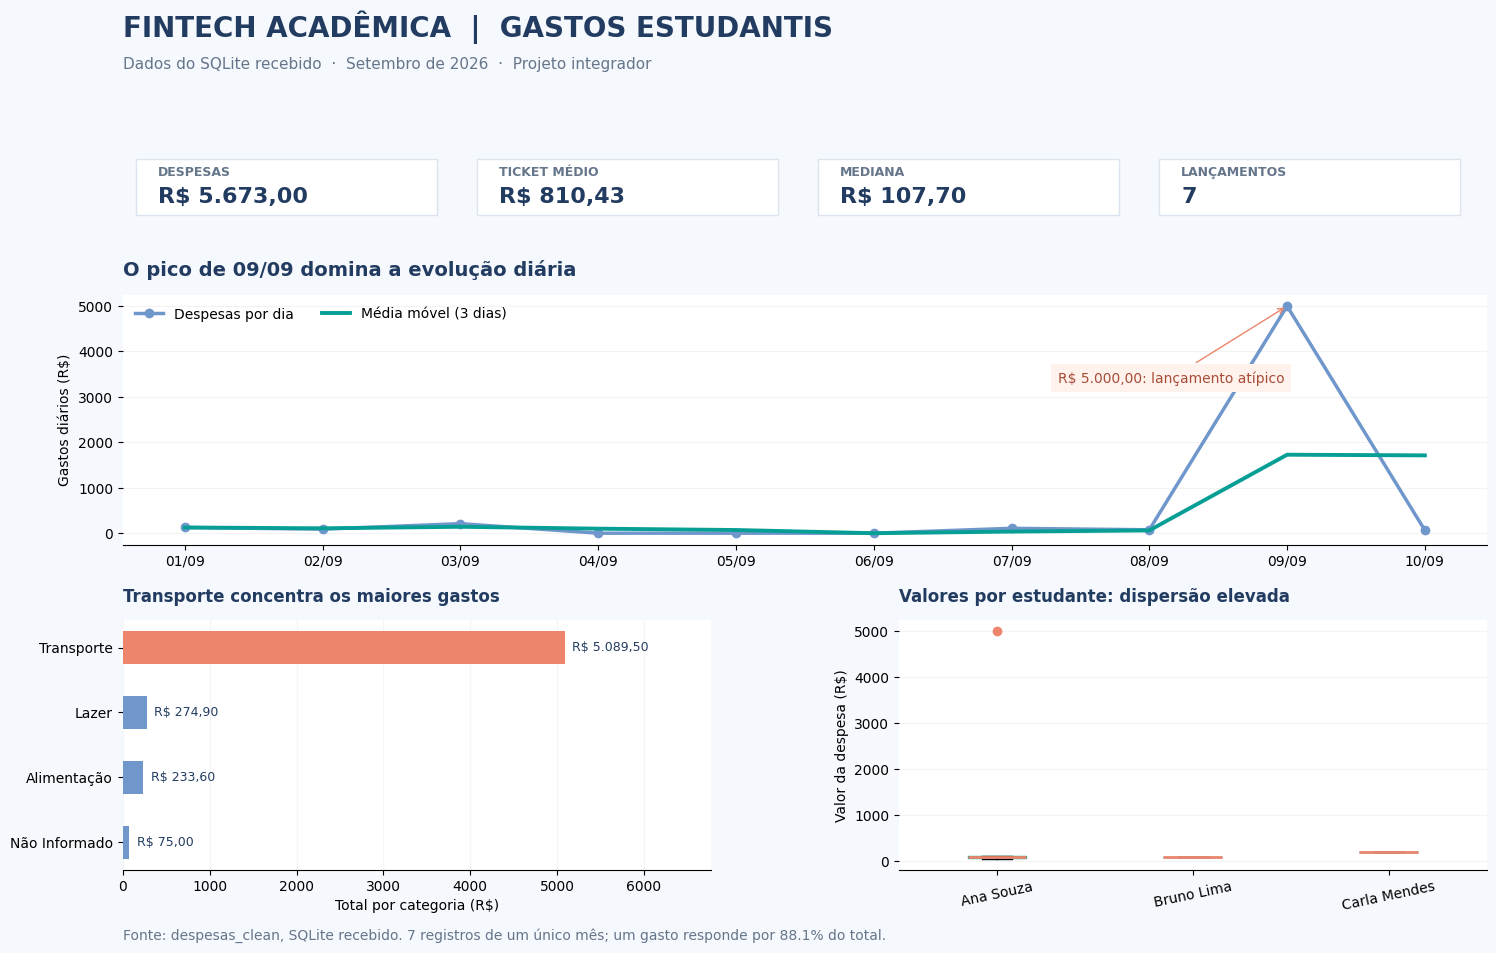

Dashboard salvo em: /mnt/data/fintech_academica_entrega_final/semana_08_storytelling_visual/dashboard_semana_08.png


In [4]:
AZUL='#223B60'; TURQUESA='#079F95'; CLARO='#7097CB'; CORAL='#EC856C'; CINZA='#65758A'; FUNDO='#F5F8FC'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10})
fig=plt.figure(figsize=(15.5,10),facecolor=FUNDO)
gr=GridSpec(4,2,figure=fig,height_ratios=[.8,.8,3.1,3.1],left=.07,right=.95,top=.95,bottom=.095,hspace=.48,wspace=.32)
ax_titulo=fig.add_subplot(gr[0,:]); ax_titulo.axis('off')
ax_titulo.text(0,.67,'FINTECH ACADÊMICA  |  GASTOS ESTUDANTIS',fontsize=20,weight='bold',color=AZUL,transform=ax_titulo.transAxes)
ax_titulo.text(0,.17,'Dados do SQLite recebido  ·  Setembro de 2026  ·  Projeto integrador',fontsize=11,color=CINZA,transform=ax_titulo.transAxes)
ax_kpis=fig.add_subplot(gr[1,:]); ax_kpis.axis('off')

def formato(n):return 'R$ '+f'{n:,.2f}'.replace(',','X').replace('.',',').replace('X','.')
kpis=[('DESPESAS',formato(TOTAL)),('TICKET MÉDIO',formato(MEDIA)),('MEDIANA',formato(MEDIANA)),('LANÇAMENTOS',str(len(despesas)))]
for i,(nome,valor) in enumerate(kpis):
    x=i*.25+.01
    ax_kpis.add_patch(plt.Rectangle((x,.06),.22,.88,facecolor='white',edgecolor='#DCE5EF',linewidth=1,transform=ax_kpis.transAxes))
    ax_kpis.text(x+.016,.67,nome,fontsize=9,weight='bold',color=CINZA,transform=ax_kpis.transAxes)
    ax_kpis.text(x+.016,.26,valor,fontsize=16,weight='bold',color=AZUL,transform=ax_kpis.transAxes)

ax_linha=fig.add_subplot(gr[2,:])
ax_linha.plot(DIARIO.index,DIARIO.values,color=CLARO,marker='o',linewidth=2.5,label='Despesas por dia')
ax_linha.plot(MEDIA_3_DIAS.index,MEDIA_3_DIAS.values,color=TURQUESA,linewidth=2.8,label='Média móvel (3 dias)')
ax_linha.annotate('R$ 5.000,00: lançamento atípico',xy=(DIARIO.idxmax(),DIARIO.max()),
                 xytext=(-165,-55),textcoords='offset points',arrowprops={'arrowstyle':'->','color':CORAL},
                 bbox={'facecolor':'#FFF2EC','edgecolor':'none','pad':5},color='#A74C37')
ax_linha.set_title('O pico de 09/09 domina a evolução diária',loc='left',fontsize=14,fontweight='bold',color=AZUL,pad=14)
ax_linha.set_ylabel('Gastos diários (R$)')
ax_linha.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
ax_linha.spines[['top','right','left']].set_visible(False)
ax_linha.grid(axis='y',alpha=.15)
ax_linha.legend(frameon=False,ncol=2,loc='upper left')

ax_bar=fig.add_subplot(gr[3,0])
cores=[CORAL if nome=='transporte' else CLARO for nome in CATEGORIAS.index]
bars=ax_bar.barh([n.replace('nao_informado','não informado').title() for n in CATEGORIAS.index],CATEGORIAS.values,color=cores,height=.5)
for bar,n in zip(bars,CATEGORIAS.values):
    ax_bar.text(n+TOTAL*.015,bar.get_y()+bar.get_height()/2,formato(n),va='center',fontsize=9,color=AZUL)
ax_bar.set_xlim(0,max(CATEGORIAS)*1.33)
ax_bar.set_title('Transporte concentra os maiores gastos',loc='left',fontsize=12,weight='bold',color=AZUL,pad=13)
ax_bar.set_xlabel('Total por categoria (R$)')
ax_bar.spines[['top','right','left']].set_visible(False)
ax_bar.grid(axis='x',alpha=.12)
ax_bar.set_axisbelow(True)

ax_box=fig.add_subplot(gr[3,1])
nomes=list(despesas.estudante.unique())
por_pessoa=[despesas.loc[despesas.estudante==nome,'valor'].tolist() for nome in nomes]
bp=ax_box.boxplot(por_pessoa,tick_labels=nomes,patch_artist=True,showfliers=True,boxprops={'facecolor':'#CAEAE8','color':TURQUESA},
                   medianprops={'color':CORAL,'linewidth':2},flierprops={'marker':'o','markerfacecolor':CORAL,'markeredgecolor':CORAL})
ax_box.set_title('Valores por estudante: dispersão elevada',loc='left',fontsize=12,weight='bold',color=AZUL,pad=13)
ax_box.set_ylabel('Valor da despesa (R$)')
ax_box.spines[['top','right','left']].set_visible(False)
ax_box.grid(axis='y',alpha=.13)
ax_box.tick_params(axis='x',labelrotation=12)

fig.text(.07,.025,f'Fonte: despesas_clean, SQLite recebido. {len(despesas)} registros de um único mês; um gasto responde por {ATIPICOS/TOTAL*100:.1f}% do total.',
         fontsize=10,color=CINZA)
destino=Path.cwd()/'dashboard_semana_08.png'
fig.savefig(destino,dpi=170,facecolor=FUNDO)
plt.show()
print('Dashboard salvo em:',destino)


## Leitura do painel

O gráfico da evolução não representa uma tendência mensal: só temos dez dias entre a primeira e a última despesa. A concentração em transporte ocorre principalmente por um registro atípico. A mediana complementa o ticket médio, que fica muito alto quando esse registro é incluído. As comparações são **descritivas**, não generalizáveis.


In [5]:
from IPython.display import display, Image
assert destino.is_file()
print('Tamanho do PNG:',destino.stat().st_size,'bytes')
conexao.close()


Tamanho do PNG: 267766 bytes
